In [1]:
from pathlib import Path
from itertools import combinations
import json, re, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from scipy.interpolate import PchipInterpolator
from scipy.ndimage import gaussian_filter1d
from helpers import interpolateData, getContours


MODEL = 'Scalar'
INPUT_PICKLE = Path('../Recast/VLFandScalar/Scalar_smodels.pcl')

# Mass columns are the ones used in the uploaded SModelS notebooks.
MASS_COL = "mass.5000002"
DM_MASS_COL = "mass.5000012"
K_FACTOR = 1.0
R_CUT = 1.0 / K_FACTOR
BLOCKED_ANALYSES = { 'CMS-PAS-EXO-16-036', 'ATLAS-SUSY-2016-32', 'CMS-PAS-SUS-16-052', 'CMS-SUS-17-005',
                   'CMS-PAS-SUS-16-052-agg', 'ATLAS-SUSY-2016-16', 'ATLAS-SUSY-2018-08', 'CMS-SUS-18-004',
                 'CMS-SUS-19-010', 'ATLAS-SUSY-2016-17' }  # Use set() to include all analyses


SHOW_TOTAL_EXCLUSION = True
FILL_EXCLUDED_REGIONS = True
FILL_LEFT_MASS = 200.0     # Exactly as in plotExclusion-DirectSearches
FILL_ALPHA = 0.18          # Exactly as in plotExclusion-DirectSearches
BENCHMARK = (1500.0, 100.0)
SHOW_BENCHMARK = True
X_LIM = (500.0, 2500.0)
Y_LIM = (50.0, 500.0)
LEGEND_FONTSIZE = 15
INTERPOLATION_RESOLUTION = 200  # auxPlots original grid used to FIND the r=1 contours

# The PCHIP smoothing you used for Zprime, adapted to M_limit(deltaM).
SMOOTH_SIGMA = 1.2          # Gaussian width IN OUTPUT GRID POINTS; 0 disables smoothing
PCHIP_KNOT_SPACING = 2.0    # GeV in deltaM, knot spacing before dense PCHIP reconstruction
BOUNDARY_NPTS = 650         # dense common deltaM grid, including both Y_LIM endpoints
FILL_GAP_TOLERANCE_Y = 3.0   # GeV; only tiny gaps between supported contours
FILL_GAP_TOLERANCE_X = 20.0  # GeV; require neighboring masses to be close
# 'individual': transparent fills for each analysis, 'total': one neutral combined fill, 'none': no fill.
FILL_STYLE = 'individual'  
# Set to {} to retain all raw discontinuities. Repairs are visualization-only.
ANALYSIS_GAP_REPAIR = {
}
SHOW_REPAIR_DIAGNOSTICS = True
# Raw combined-all contour is saved but NOT used for the black line (it is interpolated independently).

# Distinct lines with matching translucent colors.
PALETTE = [
    "#0072B2",  # Blue
    "#E41A1C",  # Red
    "#009E73",  # Green
    "#984EA3",  # Purple
    "#F781BF",  # Pink
    "#00A6A6",  # Teal
    "#4D4D4D",  # Dark gray
]

pd.option_context('display.max_columns', -1)

pd.options.mode.chained_assignment = None #Disable copy warnings
# plt.style.use('fivethirtyeight') #Set style
# mpl.rcParams.update({'figure.figsize' : (15,10)})  #Set general plotting options
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica"]})

plt.rcParams.update({"savefig.dpi" : 300}) #Figure resolution


#Define plotting style:
sns.set() #Set style
sns.set_style('ticks',{'font.family':'Times New Roman', 'font.serif':'Times New Roman'})
sns.set_context('paper', font_scale=1.8)




In [2]:
if not INPUT_PICKLE.exists():
    raise FileNotFoundError(f"Place {INPUT_PICKLE} in the working directory (or change INPUT_PICKLE).")
dataDF = pd.read_pickle(INPUT_PICKLE).reset_index(drop=True).copy()
for col in (MASS_COL, DM_MASS_COL):
    if col not in dataDF:
        raise KeyError(f"Mass column {col} not found. Available: {[c for c in dataDF if c.startswith('mass.')]}")
dataDF['deltaM'] = pd.to_numeric(dataDF[MASS_COL], errors='coerce') - pd.to_numeric(dataDF[DM_MASS_COL], errors='coerce')

# Extract all AnalysisID/r entries and keep largest reported r when an ID repeats.
indices = sorted({int(m.group(1)) for c in dataDF.columns
                  if (m := re.fullmatch(r'ExptRes\.result(\d+)\.r', c))})
parts = []
for i in indices:
    a, r = f'ExptRes.result{i}.AnalysisID', f'ExptRes.result{i}.r'
    if a not in dataDF or r not in dataDF:
        continue
    t = pd.DataFrame({'point_id': dataDF.index, 'analysis_id': dataDF[a],
                      'r': pd.to_numeric(dataDF[r], errors='coerce')})
    t = t[t.analysis_id.map(lambda v: isinstance(v, str) and bool(v.strip())) &
          np.isfinite(t.r) & (t.r >= 0)]
    parts.append(t)
if not parts:
    raise ValueError('No valid ExptRes.resultN.AnalysisID/r pairs in scan.')
longDF = pd.concat(parts, ignore_index=True)
all_analysis_r = longDF.groupby(['point_id', 'analysis_id'])['r'].max().unstack().reindex(dataDF.index)
missing_blocks = sorted(BLOCKED_ANALYSES - set(all_analysis_r.columns))
if missing_blocks:
    print('Blocked IDs not reported in this scan:', missing_blocks)
analysis_r = all_analysis_r.drop(columns=list(BLOCKED_ANALYSES), errors='ignore')
if analysis_r.shape[1] == 0:
    raise ValueError('All analysis columns were blocked.')
full_r = analysis_r.max(axis=1).fillna(0.0)
excluded_mask = full_r > R_CUT

if not BLOCKED_ANALYSES and 'ExptRes.result0.r' in dataDF:
    combined_r = pd.to_numeric(dataDF['ExptRes.result0.r'], errors='coerce').fillna(0.0)
    if not np.array_equal((combined_r > R_CUT).to_numpy(), excluded_mask.to_numpy()):
        warnings.warn('result0 differs from max(reported r) in the excluded-point classification.')
else:
    combined_r = full_r


# Smallest set of analyses reproducing the scan-point exclusion

In [3]:
coverage = {a: set(dataDF.index[analysis_r[a] > R_CUT]) for a in analysis_r.columns}
target = set(dataDF.index[excluded_mask])
active = sorted(a for a in coverage if coverage[a])

def minimum_cover(active, coverage, target, table):
    if not target:
        return [], 1
    if set().union(*(coverage[a] for a in active)) != target:
        raise RuntimeError('The reported analyses cannot cover the full excluded set.')
    for size in range(1, len(active) + 1):
        candidates = [subset for subset in combinations(active, size)
                      if set().union(*(coverage[a] for a in subset)) == target]
        if candidates:
           
            def score(subset):
                values = table.loc[sorted(target), list(subset)].to_numpy(dtype=float)
                return np.where(values > R_CUT, values, -np.inf).max(axis=1).sum()
            return list(max(candidates, key=score)), len(candidates)
    raise RuntimeError('No covering set could be found.')

minimal_analyses, n_equal = minimum_cover(active, coverage, target, analysis_r)
selected_r = (analysis_r[minimal_analyses].max(axis=1).fillna(0.0)
              if minimal_analyses else pd.Series(0.0, index=dataDF.index))
assert np.array_equal((selected_r > R_CUT).to_numpy(), excluded_mask.to_numpy())

best_selected = pd.Series(None, index=dataDF.index, dtype=object)
if minimal_analyses and target:
    best_selected.loc[excluded_mask] = analysis_r.loc[excluded_mask, minimal_analyses].idxmax(axis=1)
summary = pd.DataFrame([{'analysis_id': a,
                         'excluded_points': len(coverage[a]),
                         'unique_points': len(coverage[a] - set().union(*(coverage[b] for b in minimal_analyses if b != a))),
                         'assigned_points': int((best_selected == a).sum())}
                        for a in minimal_analyses],
                       columns=['analysis_id', 'excluded_points', 'unique_points', 'assigned_points'])
if not summary.empty:
    summary = summary.sort_values(['excluded_points', 'analysis_id'], ascending=[False, True])
color_by_analysis = {a: PALETTE[i % len(PALETTE)] for i, a in enumerate(minimal_analyses)}
print(f'Minimum set: {len(minimal_analyses)}/{len(active)} analyses, {n_equal} equally small solutions.')
print(summary.to_string(index=False))

Minimum set: 3/15 analyses, 1 equally small solutions.
       analysis_id  excluded_points  unique_points  assigned_points
ATLAS-SUSY-2018-12               73             48               48
    CMS-SUS-20-002               58             12               42
CMS-SUS-19-006-agg               51              5               21


##  Excluded scan points by their most sensitive selected analysis

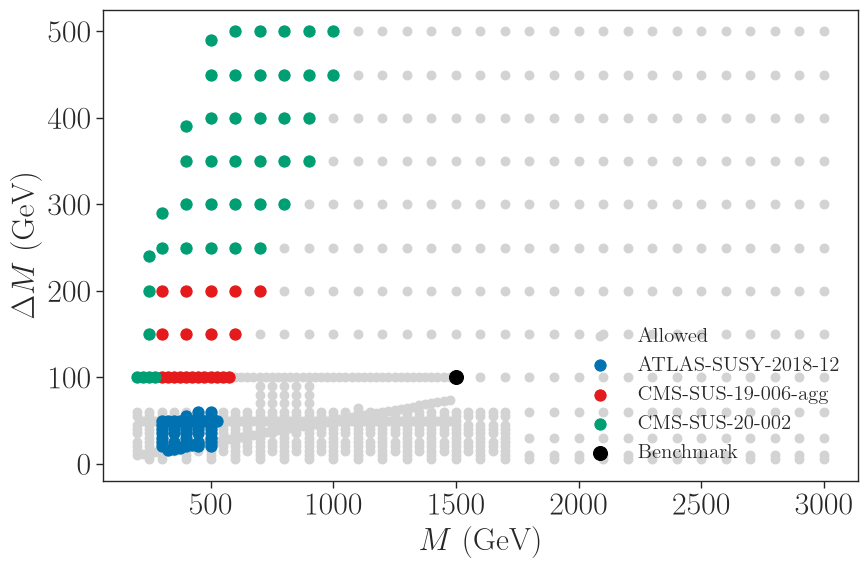

In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
allowed = dataDF.loc[~excluded_mask]
ax.scatter(allowed[MASS_COL], allowed.deltaM, s=40, c='lightgray', label='Allowed')
for ana in minimal_analyses:
    p = dataDF.loc[best_selected == ana]
    ax.scatter(p[MASS_COL], p.deltaM, s=65, color=color_by_analysis[ana], label=ana)
if SHOW_BENCHMARK:
    ax.scatter(*BENCHMARK, c='black', edgecolors='black', s=100, label='Benchmark', zorder=7)
ax.set_xlabel(r'$M$ (GeV)', fontsize=23)
ax.set_ylabel(r'$\Delta M$ (GeV)', fontsize=23)
#ax.set_xlim(*X_LIM); ax.set_ylim(*Y_LIM)
ax.tick_params(axis='both', labelsize=23)
ax.legend(loc='lower right', fontsize=LEGEND_FONTSIZE, framealpha=0)
fig.tight_layout()
plt.show()

In [5]:
def get_original_contour_segments(values, name):
    points = pd.DataFrame({'x': pd.to_numeric(dataDF[MASS_COL], errors='coerce'),
                           'y': pd.to_numeric(dataDF.deltaM, errors='coerce'),
                           'r': pd.to_numeric(values, errors='coerce')})
    points = points.replace([np.inf, -np.inf], np.nan).dropna()

    # Original SModelS notebook's chosen filters:
    cond2 = points.x.between(500, 1000) & np.isclose(points.y, 80.0)
    cond3 = points.y <= 7.0
    points = points.loc[~(cond2 | cond3)]
    # Exact-coordinate duplicates must have a unique value for griddata.
    points = points.groupby(['x', 'y'], as_index=False)['r'].max()
    if (len(points) < 3 or points.x.nunique() < 2 or points.y.nunique() < 2 or
            not (points.r.min() < R_CUT < points.r.max())):
        return []

    xnew, ynew, znew = interpolateData(points.x.to_numpy(), points.y.to_numpy(),
                                      points.r.to_numpy(), nx=INTERPOLATION_RESOLUTION,
                                      ny=INTERPOLATION_RESOLUTION, fill_value=np.nan)
    if xnew is None:
        return []
    original_flat = getContours(xnew, ynew, znew, [R_CUT]).get(R_CUT)
    fig_tmp, ax_tmp = plt.subplots()
    try:
        contour = ax_tmp.contour(xnew, ynew, znew, [R_CUT])
        segments = [np.asarray(s, dtype=float).copy() for s in contour.allsegs[0]
                    if len(s) >= 2 and np.isfinite(s).all()]
    finally:
        plt.close(fig_tmp)
    if original_flat is not None and segments:
        assert np.allclose(np.vstack(segments), original_flat), 'Original contour vertices changed.'
    return segments

analysis_contours = {a: get_original_contour_segments(analysis_r[a], a)
                     for a in minimal_analyses}
full_contours = get_original_contour_segments(combined_r, 'Total')
minimal_contours = get_original_contour_segments(selected_r, 'Selected combined')

for a, segments in analysis_contours.items():
    print(f'{a}: {len(segments)} disconnected contour piece(s)')
print('Reference-style total:', len(full_contours), 'piece(s)')

# --- Analogue of the Zprime plot_simple_fill: M_limit(deltaM) ---
DELTA_GRID = np.linspace(Y_LIM[0], Y_LIM[1], BOUNDARY_NPTS)
DY = DELTA_GRID[1] - DELTA_GRID[0]


def rightmost_crossings(segments, y_grid):
    """Take the rightmost crossing of the actual contour polylines at each horizontal slice.

    No interpolation between different disconnected raw contour segments occurs here.
    A contour segment is a continuous polyline, possibly looping back in mass.
    """
    right = np.full(len(y_grid), np.nan)
    for seg in segments:
        if len(seg) < 2:
            continue
        xy = np.asarray(seg, dtype=float)
        xa, xb = xy[:-1, 0], xy[1:, 0]
        ya, yb = xy[:-1, 1], xy[1:, 1]
        ymin, ymax = np.minimum(ya, yb), np.maximum(ya, yb)
        lo, hi = np.searchsorted(y_grid, [ymin.min(), ymax.max()])
        for k in range(max(0, lo - 1), min(len(y_grid), hi + 2)):
            y = y_grid[k]
            cross = (y >= ymin - 1e-9) & (y <= ymax + 1e-9)
            if not cross.any():
                continue
            horizontal = cross & np.isclose(ya, yb, atol=1e-11)
            rising = cross & ~horizontal
            xx = []
            if rising.any():
                xx.append(np.max(xa[rising] + (y - ya[rising]) * (xb[rising] - xa[rising]) / (yb[rising] - ya[rising])))
            if horizontal.any():
                xx.append(np.max(np.maximum(xa[horizontal], xb[horizontal])))
            if xx:
                value = max(xx)
                right[k] = value if not np.isfinite(right[k]) else max(value, right[k])
    return right


def bridge_tiny_gaps(values, y_grid, max_delta_y, max_delta_m):
    """Join ONLY short unsupported runs with compatible mass endpoints.

    No extension past the first or last supported point, hence a short analysis
    cannot produce color above/below its own contour's deltaM range.
    """
    out = values.copy()
    valid = np.flatnonzero(np.isfinite(out))
    for i, j in zip(valid[:-1], valid[1:]):
        if j <= i + 1:
            continue
        if y_grid[j] - y_grid[i] <= max_delta_y and abs(out[j] - out[i]) <= max_delta_m:
            out[i + 1:j] = np.interp(y_grid[i + 1:j], [y_grid[i], y_grid[j]], [out[i], out[j]])
    return out


def contiguous_slices(valid):
    ids = np.flatnonzero(valid)
    if ids.size == 0:
        return []
    splits = np.where(np.diff(ids) > 1)[0] + 1
    return [chunk for chunk in np.split(ids, splits) if len(chunk)]


def smooth_right_boundary(segments, y_grid=DELTA_GRID, analysis_name=None):
    """PCHIP + light Gaussian, separately on each connected support interval."""
    raw = rightmost_crossings(segments, y_grid)
    raw = bridge_tiny_gaps(raw, y_grid, FILL_GAP_TOLERANCE_Y, FILL_GAP_TOLERANCE_X)
    if analysis_name in ANALYSIS_GAP_REPAIR:
        opts = ANALYSIS_GAP_REPAIR[analysis_name]
        old_valid = np.isfinite(raw)
        raw = bridge_tiny_gaps(raw, y_grid, opts['max_delta_y'], opts['max_delta_m'])
        repaired = np.flatnonzero(np.isfinite(raw) & ~old_valid)
        if SHOW_REPAIR_DIAGNOSTICS:
            print(f'{analysis_name}: repaired {len(repaired)} internal slice(s); '
                  f'gap bounds: deltaM<={opts["max_delta_y"]:g} GeV, '
                  f'|delta mass|<={opts["max_delta_m"]:g} GeV')
    result = np.full(len(y_grid), np.nan)
    for ids in contiguous_slices(np.isfinite(raw)):
        yy, xx = y_grid[ids], raw[ids]
        if len(ids) < 2:
            result[ids] = xx
            continue
        stride = max(1, int(round(PCHIP_KNOT_SPACING / (y_grid[1] - y_grid[0]))))
        keep = np.unique(np.r_[np.arange(0, len(ids), stride), len(ids) - 1])
        interp = PchipInterpolator(yy[keep], xx[keep])(yy) if len(keep) >= 2 else xx.copy()
        if SMOOTH_SIGMA > 0 and len(ids) >= 3:
            interp = gaussian_filter1d(interp, sigma=SMOOTH_SIGMA, mode='nearest')
        # The plotted line and shaded region use EXACTLY these same values.
        result[ids] = interp
    return result


smoothed_analysis = {a: smooth_right_boundary(analysis_contours[a], analysis_name=a) for a in minimal_analyses}
if smoothed_analysis:
    # Every finite combined point equals a selected analysis's boundary, to floating-point precision.
    stack = np.vstack([smoothed_analysis[a] for a in minimal_analyses])
    combined_smoothed = np.max(np.where(np.isfinite(stack), stack, -np.inf), axis=0)
    combined_smoothed[~np.isfinite(combined_smoothed)] = np.nan
    for a in minimal_analyses:
        valid = np.isfinite(smoothed_analysis[a])
        assert np.all(combined_smoothed[valid] >= smoothed_analysis[a][valid] - 1e-9)
else:
    combined_smoothed = np.full(len(DELTA_GRID), np.nan)

print('Smoothed boundary supports (deltaM in GeV):')
for a in minimal_analyses:
    valid = np.isfinite(smoothed_analysis[a])
    print(f'  {a}: [{DELTA_GRID[valid].min():.1f}, {DELTA_GRID[valid].max():.1f}]' if valid.any()
          else f'  {a}: no supported boundary')


ATLAS-SUSY-2018-12: 1 disconnected contour piece(s)
CMS-SUS-19-006-agg: 1 disconnected contour piece(s)
CMS-SUS-20-002: 2 disconnected contour piece(s)
Reference-style total: 3 piece(s)
Smoothed boundary supports (deltaM in GeV):
  ATLAS-SUSY-2018-12: [50.0, 500.0]
  CMS-SUS-19-006-agg: [92.3, 500.0]
  CMS-SUS-20-002: [92.3, 500.0]


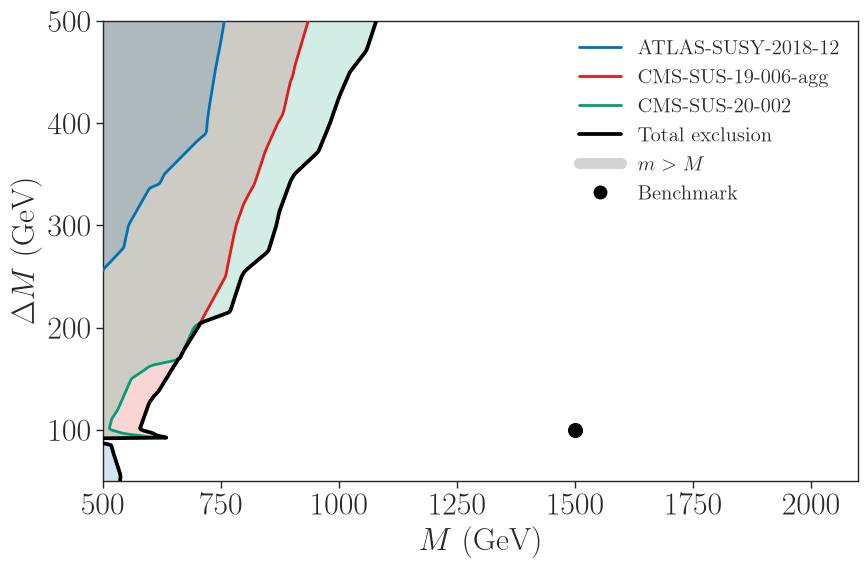

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))


def draw_supported_curve(ax, x_limit, color, *, lw=2.0, label=None, fill=False, zorder=3):
    """One PCHIP/Gaussian boundary: identical coordinates for line and fill."""
    first = True
    for ids in contiguous_slices(np.isfinite(x_limit)):
        if len(ids) < 2:
            continue
        yy, xx = DELTA_GRID[ids], x_limit[ids]
        ax.plot(xx, yy, color=color, linewidth=lw, label=label if first else None, zorder=zorder)
        if fill:
            # Shade only within this contour's actual deltaM support.
            ax.fill_betweenx(yy, FILL_LEFT_MASS, xx, where=xx >= FILL_LEFT_MASS,
                             color=color, alpha=FILL_ALPHA, linewidth=0, zorder=1)
        first = False


if FILL_EXCLUDED_REGIONS and FILL_STYLE == 'total':
    # Optional neutral fill makes short-analysis endpoints less visually distracting.
    for ids in contiguous_slices(np.isfinite(combined_smoothed)):
        if len(ids) < 2:
            continue
        ax.fill_betweenx(DELTA_GRID[ids], FILL_LEFT_MASS, combined_smoothed[ids],
                         color='0.75', alpha=0.35, linewidth=0, zorder=1)

for a in minimal_analyses:
    draw_supported_curve(ax, smoothed_analysis[a], color=color_by_analysis[a], lw=2.0,
                         fill=FILL_EXCLUDED_REGIONS and FILL_STYLE == 'individual')

legend = [Line2D([0], [0], color=color_by_analysis[a], lw=2, label=a)
          for a in minimal_analyses if np.isfinite(smoothed_analysis[a]).any()]
if SHOW_TOTAL_EXCLUSION:
    draw_supported_curve(ax, combined_smoothed, color='black', lw=2.7, zorder=5)
    if np.isfinite(combined_smoothed).any():
        legend.append(Line2D([0], [0], color='black', lw=2.7, label='Total exclusion'))

# Original reference's unphysical region and benchmark.
ax.fill_betweenx([200.0, 600.0], [200.0, 600.0], color='lightgray', alpha=1, zorder=2)
legend.append(Line2D([0], [0], color='lightgray', lw=8, label=r'$m > M$'))
if SHOW_BENCHMARK:
    ax.scatter(*BENCHMARK, c='black', edgecolors='black', s=100, zorder=7)
    legend.append(Line2D([0], [0], marker='o', color='black', linestyle='None',
                         markersize=9, label='Benchmark'))

ax.legend(handles=legend, loc='upper right', fontsize=LEGEND_FONTSIZE, framealpha=0)
ax.set_xlabel(r'$M$ (GeV)', fontsize=23)
ax.set_ylabel(r'$\Delta M$ (GeV)', fontsize=23)
ax.set_xlim((500.0, 2100.0)); ax.set_ylim((50, 500))
ax.tick_params(axis='both', labelsize=23)
fig.tight_layout()
fig.savefig( 'minimum_analysis_curves_Scalar.png', bbox_inches='tight')
plt.show()


In [7]:
# Save only the contours used in the exclusion plot

curve_columns = [
    'curve_type', 'analysis_id', 'segment_id', 'vertex_id',
    'mass_GeV', 'deltaM_GeV', 'r_cut', 'K_factor'
]

def store_curve(rows, curve_type, analysis_id, x_limit):
    """Store the exact smoothed contour coordinates used in the plot."""
    for segment_id, ids in enumerate(contiguous_slices(np.isfinite(x_limit))):
        if len(ids) < 2:
            continue

        for vertex_id, k in enumerate(ids):
            rows.append({
                'curve_type': curve_type,
                'analysis_id': analysis_id,
                'segment_id': segment_id,
                'vertex_id': vertex_id,
                'mass_GeV': float(x_limit[k]),
                'deltaM_GeV': float(DELTA_GRID[k]),
                'r_cut': R_CUT,
                'K_factor': K_FACTOR
            })


# Individual analyses in the minimal subset
curve_rows = []

for a in minimal_analyses:
    store_curve(curve_rows, 'analysis', a, smoothed_analysis[a])

# Total exclusion (saved even if SHOW_TOTAL_EXCLUSION = False)
store_curve(curve_rows, 'combined_minimal', 'MINIMAL', combined_smoothed)

# Single DataFrame containing all plotted contours
curvesDF = pd.DataFrame(curve_rows, columns=curve_columns)

# Save in both formats (remove either line if you only need one)
curvesDF.to_pickle('exclusion_curves_Scalar.pkl')

